In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

daten = pd.read_csv("data/bus48_modell.csv", parse_dates=["tag", "planzeit"])

ZAHLEN = ["stunde", "wochentag", "wochenende", "schulferien", "temp", "regen_mm"]
KATEGORIEN = ["HALTESTELLEN_NAME", "richtung"]

# Text-Merkmale in 0/1-Spalten umwandeln (One-Hot-Encoding)
X = pd.get_dummies(daten[ZAHLEN + KATEGORIEN], columns=KATEGORIEN, dtype=int)
y = daten["verspaetung_min"]

print("Abfahrten:", len(X), "· Merkmale:", X.shape[1])
X.columns.tolist()[:12]

Abfahrten: 183541 · Merkmale: 27


['stunde',
 'wochentag',
 'wochenende',
 'schulferien',
 'temp',
 'regen_mm',
 'HALTESTELLEN_NAME_Bahnhof SBB',
 'HALTESTELLEN_NAME_Bahnhof St.Johann',
 'HALTESTELLEN_NAME_Basel Bachgraben',
 'HALTESTELLEN_NAME_Belforterstrasse',
 'HALTESTELLEN_NAME_Felix Platter-Spital',
 'HALTESTELLEN_NAME_Gartenstrasse']

In [ ]:
GRENZE = pd.Timestamp("2026-10-26")

train = daten["tag"] < GRENZE
test = ~train

X_train, X_test = X[train], X[test]
y_train, y_test = y[train], y[test]

print("Training:", daten.loc[train, "tag"].nunique(), "Tage ·", len(X_train), "Abfahrten")
print("Test:    ", daten.loc[test, "tag"].nunique(), "Tage ·", len(X_test), "Abfahrten")

Training: 85 Tage · 168360 Abfahrten
Test:     7 Tage · 15181 Abfahrten


In [ ]:
from sklearn.metrics import mean_absolute_error

schnitt = daten[train].groupby(["richtung", "stunde"])["verspaetung_min"].mean()
schluessel = list(zip(daten.loc[test, "richtung"], daten.loc[test, "stunde"]))
baseline = pd.Series(schluessel, index=X_test.index).map(schnitt).fillna(y_train.mean())

print(f"Baseline: im Schnitt {mean_absolute_error(y_test, baseline):.2f} Min. daneben")

Baseline: im Schnitt 1.33 Min. daneben


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score

modelle = {
    "Lineare Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=20,
                                           n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
}

ergebnisse = {}
for name, modell in modelle.items():
    modell.fit(X_train, y_train)
    vorhersage = modell.predict(X_test)
    ergebnisse[name] = vorhersage
    print(f"{name:20s}  daneben: {mean_absolute_error(y_test, vorhersage):.2f} Min.   "
          f"R²: {r2_score(y_test, vorhersage):.2f}")

Lineare Regression    daneben: 1.39 Min.   R²: 0.02
Random Forest         daneben: 1.30 Min.   R²: 0.14
Gradient Boosting     daneben: 1.29 Min.   R²: 0.14


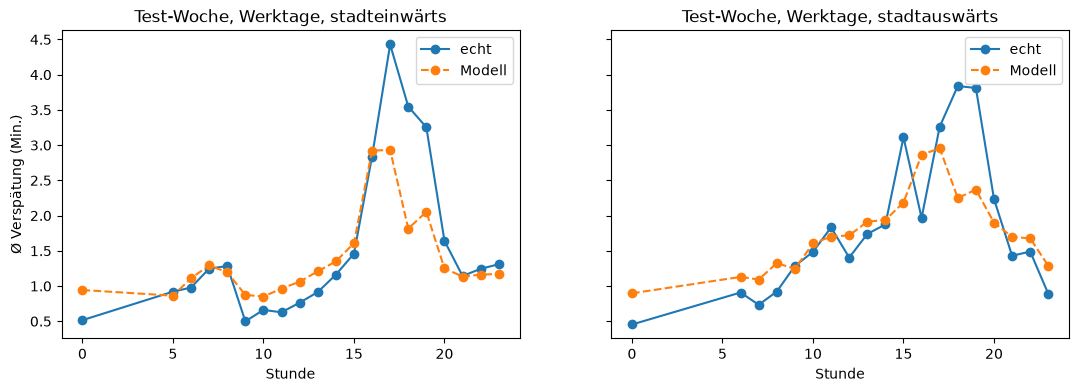

In [ ]:
bestes = "Gradient Boosting"
vergleich = daten[test].assign(vorhersage=ergebnisse[bestes])
werktage = vergleich[~vergleich["wochenende"]]

fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, richtung in zip(ax, ["stadteinwärts", "stadtauswärts"]):
    teil = werktage[werktage["richtung"] == richtung].groupby("stunde")
    a.plot(teil["verspaetung_min"].mean(), "o-", label="echt")
    a.plot(teil["vorhersage"].mean(), "o--", label="Modell")
    a.set_title(f"Test-Woche, Werktage, {richtung}")
    a.set_xlabel("Stunde")
    a.legend()
ax[0].set_ylabel("Ø Verspätung (Min.)")
plt.show()

In [ ]:
def verspaetung_vorhersagen(haltestelle, richtung, stunde, wochentag, regen_mm=0.0, temp=10.0, schulferien=False):
    zeile = pd.DataFrame([{
        "stunde": stunde, "wochentag": wochentag, "wochenende": wochentag >= 5,
        "schulferien": schulferien, "temp": temp, "regen_mm": regen_mm,
        "HALTESTELLEN_NAME": haltestelle, "richtung": richtung,
    }])
    zeile = pd.get_dummies(zeile, columns=KATEGORIEN, dtype=int).reindex(columns=X.columns, fill_value=0)
    return modelle[bestes].predict(zeile)[0]

print(f"Di 07 Uhr, Ziegelei → Stadt, trocken: {verspaetung_vorhersagen('Ziegelei', 'stadteinwärts', 7, 1):.1f} Min.")
print(f"Do 17 Uhr, Ziegelei → Stadt, Regen:   {verspaetung_vorhersagen('Ziegelei', 'stadteinwärts', 17, 3, regen_mm=3):.1f} Min.")
print(f"Do 17 Uhr, SBB → Allschwil, Regen:    {verspaetung_vorhersagen('Bahnhof SBB', 'stadtauswärts', 17, 3, regen_mm=3):.1f} Min.")

Di 07 Uhr, Ziegelei → Stadt, trocken: 1.3 Min.
Do 17 Uhr, Ziegelei → Stadt, Regen:   4.0 Min.
Do 17 Uhr, SBB → Allschwil, Regen:    2.0 Min.
